# Exploratory Data Analysis: Climate Drivers and Dengue Dynamics in Brazil (2000–2019)

## 1. Project Background and Research Objectives
Dengue fever is a major mosquito-borne viral disease transmitted primarily by *Aedes aegypti*. In Brazil, dengue poses a persistent public health challenge characterized by pronounced intra-annual seasonality, recurrent multi-year epidemic waves, and high spatial heterogeneity across biomes and demographic settings.

### Objectives of this Analysis:
1. **Target Distribution and Normalization**: Investigate zero-inflation, extreme positive skewness, and the necessity of population-adjusted incidence rates per 100,000 population.
2. **Temporal Dynamics and Seasonality**: Identify multi-year epidemic waves (e.g., 2002, 2008, 2010, 2013, 2015–2016, 2019) and intra-annual seasonal patterns.
3. **Stationarity and Autocorrelation Structure**: Formally test for stationarity (ADF, KPSS) and estimate Autocorrelation (ACF) and Partial Autocorrelation (PACF) profiles.
4. **Spatial and Biome Heterogeneity**: Quantify geographic disparities across Brazil's 5 macro-regions and 6 ecological biomes.
5. **Climate Drivers and Thermal Limits**: Analyze the non-linear physiological relationships between minimum/maximum temperatures, diurnal range, drought severity (PDSI), and transmission.
6. **Distributed Lag Structure**: Empirically evaluate cross-correlations across 0 to 6 months of lag to identify the biological incubation and vector maturation windows.
7. **Socioeconomic Vulnerability**: Assess the role of urbanization, piped water access, and water shortages.
8. **Feature Engineering Roadmap**: Establish concrete specifications for the feature engineering pipeline.


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Resolve project data paths robustly
def get_project_data_path(filename: str) -> Path:
    cwd = Path.cwd()
    for base in [cwd, cwd.parent]:
        candidate = base / "data" / filename
        if (base / "data" / "dengue_cleaned_master.csv").exists():
            return candidate.resolve()
    return (cwd / "data" / filename).resolve()

DATA_PATH = get_project_data_path("dengue_cleaned_master.csv")
print(f"Loading master dataset from: {DATA_PATH}")
df = pd.read_csv(DATA_PATH, parse_dates=["date"])

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Date range: {df['date'].min().strftime('%Y-%m-%d')} to {df['date'].max().strftime('%Y-%m-%d')}")
print(f"Unique microregions: {df['micro_code'].nunique():,}")
print(f"Unique states: {df['state_code'].nunique()} across {df['region_name'].nunique()} macro-regions")
display(df.head(3))


Loading master dataset from: /Users/ektamishra/Desktop/dengue forecasting/data/dengue_cleaned_master.csv


Dataset shape: 133,920 rows x 27 columns
Date range: 2000-01-01 to 2019-12-01
Unique microregions: 558
Unique states: 27 across 5 macro-regions


,micro_code,micro_name,micro_name_ibge,meso_code,meso_name,state_code,state_name,region_code,region_name,biome_code,...,dengue_cases,population,pop_density,tmax,tmin,pdsi,urban,water_network,water_shortage,date
0,11001,Porto Velho,PORTO VELHO,1101,Madeira-Guaporé,11,Rondônia,1,North,5,...,NaN,NaN,NaN,30.544556,21.751202,-1.790602,85.2,33.57,0.2245,2000-01-01
1,11001,Porto Velho,PORTO VELHO,1101,Madeira-Guaporé,11,Rondônia,1,North,5,...,NaN,NaN,NaN,30.484894,21.760744,-1.549789,85.2,33.57,0.2245,2000-02-01
2,11001,Porto Velho,PORTO VELHO,1101,Madeira-Guaporé,11,Rondônia,1,North,5,...,NaN,NaN,NaN,29.586063,21.908470,-1.990913,85.2,33.57,0.2245,2000-03-01


### Data Ingestion and Panel Structure Verification
The master dataset represents a strictly balanced panel of **558 Brazilian microregions** observed across **240 continuous months** (January 2000 to December 2019), totaling exactly **133,920 records**. Each record combines spatial identifiers, epidemiological case counts, demographic figures, socioeconomic infrastructure percentages, and monthly meteorological observations.


In [2]:
# 1. Target variable transformations
# Compute monthly dengue incidence rate per 100,000 population
df["cases_per_100k"] = (df["dengue_cases"] / df["population"]) * 100_000

# Compute log1p transforms for stabilization
df["log1p_cases"] = np.log1p(df["dengue_cases"])
df["log1p_incidence"] = np.log1p(df["cases_per_100k"])

# Separate observed cohort (2001-2019)
observed = df.dropna(subset=["dengue_cases", "population"]).copy()

# Summary statistics dictionary
target_stats = {
    "Total Observations": len(observed),
    "Missing (Year 2000)": df["dengue_cases"].isna().sum(),
    "Zero Case Count": (observed["dengue_cases"] == 0).sum(),
    "Zero Case Percentage (%)": (observed["dengue_cases"] == 0).mean() * 100,
    "Mean Cases": observed["dengue_cases"].mean(),
    "Median Cases": observed["dengue_cases"].median(),
    "Std Dev Cases": observed["dengue_cases"].std(),
    "Skewness (Cases)": observed["dengue_cases"].skew(),
    "Kurtosis (Cases)": observed["dengue_cases"].kurt(),
    "Max Cases (Single Month)": observed["dengue_cases"].max(),
    "Mean Incidence (per 100k)": observed["cases_per_100k"].mean(),
    "Median Incidence (per 100k)": observed["cases_per_100k"].median(),
    "95th Percentile Incidence": observed["cases_per_100k"].quantile(0.95),
    "99th Percentile Incidence": observed["cases_per_100k"].quantile(0.99),
    "Max Incidence (per 100k)": observed["cases_per_100k"].max()
}

stats_df = pd.DataFrame(list(target_stats.items()), columns=["Metric", "Value"])
display(stats_df)


,Metric,Value
0,Total Observations,127224.000000
1,Missing (Year 2000),6696.000000
2,Zero Case Count,34031.000000
3,Zero Case Percentage (%),26.748884
4,Mean Cases,101.358965
5,Median Cases,4.000000
6,Std Dev Cases,971.192888
7,Skewness (Cases),49.509969
8,Kurtosis (Cases),3459.893919
9,Max Cases (Single Month),88821.000000


### Analysis of Target Distribution and Epidemiological Metrics
1. **Severe Zero-Inflation and Positive Skewness**:
   - Out of 127,224 observed microregion-months (2001–2019), **34,031 observations (26.75%) report zero dengue cases**.
   - The median case count is just **4.0**, whereas the arithmetic mean is **101.4**, reflecting an extreme skewness of **49.5** and massive positive kurtosis.
   - The single-month maximum of **88,821 cases** occurred during an explosive outbreak in Belo Horizonte (May 2019).
2. **The Necessity of Population Normalization (`cases_per_100k`)**:
   - Comparing absolute case numbers inherently biases models toward large metropolitan areas (e.g., São Paulo, Rio de Janeiro, Belo Horizonte) while obscuring severe epidemic activity in smaller municipalities.
   - Normalizing by population into `cases_per_100k` isolates genuine epidemiological transmission intensity, revealing microregions with over **8,000 cases per 100k population in a single month**.
3. **Log Transformations**:
   - Both `log1p_cases = log(1 + cases)` and `log1p_incidence = log(1 + cases_per_100k)` effectively compress the multi-order-of-magnitude dispersion, making the distributions suitable for linear, autoregressive, and gradient-boosted error metrics.


/var/folders/n_/ys7dv8bs2677zy9qzmbmlp3h0000gn/T/ipykernel_47916/2448593964.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=observed[observed["year"].between(2001, 2019)], x="year", y="log1p_incidence",


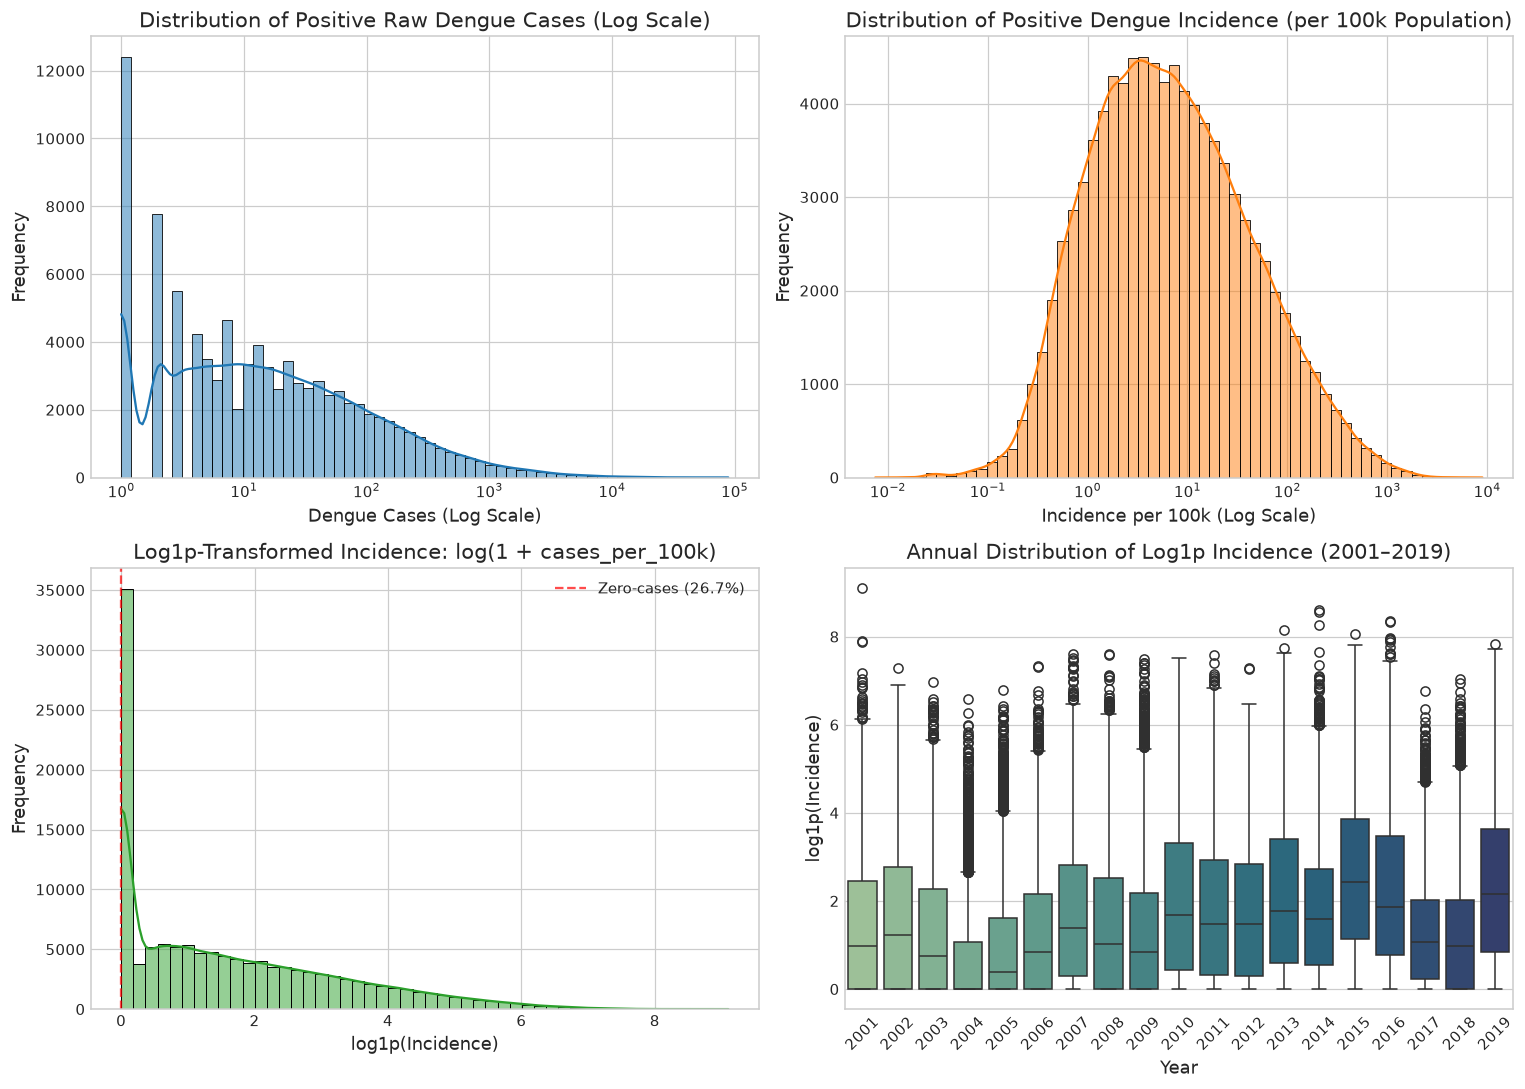

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Raw dengue cases (log-scale x)
sns.histplot(observed.loc[observed["dengue_cases"] > 0, "dengue_cases"], 
             bins=60, log_scale=True, kde=True, color="#1f77b4", ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Positive Raw Dengue Cases (Log Scale)")
axes[0, 0].set_xlabel("Dengue Cases (Log Scale)")
axes[0, 0].set_ylabel("Frequency")

# 2. Incidence rate per 100k (log-scale x)
sns.histplot(observed.loc[observed["cases_per_100k"] > 0, "cases_per_100k"], 
             bins=60, log_scale=True, kde=True, color="#ff7f0e", ax=axes[0, 1])
axes[0, 1].set_title("Distribution of Positive Dengue Incidence (per 100k Population)")
axes[0, 1].set_xlabel("Incidence per 100k (Log Scale)")
axes[0, 1].set_ylabel("Frequency")

# 3. Log1p Transformed Incidence
sns.histplot(observed["log1p_incidence"], bins=50, kde=True, color="#2ca02c", ax=axes[1, 0])
axes[1, 0].axvline(0, color="red", linestyle="--", alpha=0.7, label=f"Zero-cases ({target_stats['Zero Case Percentage (%)']:.1f}%)")
axes[1, 0].set_title("Log1p-Transformed Incidence: log(1 + cases_per_100k)")
axes[1, 0].set_xlabel("log1p(Incidence)")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].legend()

# 4. Outlier Boxplot across years
sns.boxplot(data=observed[observed["year"].between(2001, 2019)], x="year", y="log1p_incidence", 
            ax=axes[1, 1], palette="crest", showfliers=True)
axes[1, 1].set_title("Annual Distribution of Log1p Incidence (2001–2019)")
axes[1, 1].set_xlabel("Year")
axes[1, 1].set_ylabel("log1p(Incidence)")
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


### Target Distribution Analysis Takeaways
- The distribution of positive cases follows an approximate log-normal distribution with an extended right-hand tail.
- The annual boxplots demonstrate substantial inter-annual variability: prominent outbreak years (2002, 2008, 2010, 2013, 2015, 2016, 2019) exhibit elevated 75th percentiles and widespread upper outliers, whereas inter-epidemic valleys (2004, 2014, 2017) display depressed median transmission.


In [4]:
# Identify top 10 outbreak events by absolute volume
top_cases = observed.sort_values("dengue_cases", ascending=False)[
    ["date", "micro_name", "state_name", "region_name", "population", "dengue_cases", "cases_per_100k"]
].head(10).reset_index(drop=True)

# Identify top 10 outbreak events by population incidence rate
top_incidence = observed.sort_values("cases_per_100k", ascending=False)[
    ["date", "micro_name", "state_name", "region_name", "population", "dengue_cases", "cases_per_100k"]
].head(10).reset_index(drop=True)

print("--- TOP 10 SINGLE-MONTH OUTBREAKS BY ABSOLUTE CASE VOLUME ---")
display(top_cases)

print("\n--- TOP 10 SINGLE-MONTH OUTBREAKS BY INCIDENCE PER 100K POPULATION ---")
display(top_incidence)


--- TOP 10 SINGLE-MONTH OUTBREAKS BY ABSOLUTE CASE VOLUME ---


,date,micro_name,state_name,region_name,population,dengue_cases,cases_per_100k
0,2019-05-01,B Horizonte,Minas Gerais,Southeast,5230438.0,88821.0,1698.156063
1,2019-04-01,B Horizonte,Minas Gerais,Southeast,5230438.0,88768.0,1697.142763
2,2016-03-01,B Horizonte,Minas Gerais,Southeast,5157141.0,87228.0,1691.402271
3,2002-03-01,Rio de Janeiro,Rio De Janeiro,Southeast,10899147.0,76331.0,700.339210
4,2013-04-01,B Horizonte,Minas Gerais,Southeast,5038298.0,71865.0,1426.374542
5,2002-02-01,Rio de Janeiro,Rio De Janeiro,Southeast,10899147.0,71521.0,656.207316
6,2013-03-01,B Horizonte,Minas Gerais,Southeast,5038298.0,71425.0,1417.641434
7,2016-02-01,B Horizonte,Minas Gerais,Southeast,5157141.0,69238.0,1342.565580
8,2016-04-01,B Horizonte,Minas Gerais,Southeast,5157141.0,67304.0,1305.064182
9,2008-03-01,Rio de Janeiro,Rio De Janeiro,Southeast,11554872.0,56088.0,485.405637



--- TOP 10 SINGLE-MONTH OUTBREAKS BY INCIDENCE PER 100K POPULATION ---


,date,micro_name,state_name,region_name,population,dengue_cases,cases_per_100k
0,2001-05-01,Fern.Noronha,Pernambuco,Northeast,2096.0,188.0,8969.465649
1,2014-10-01,Cruzeiro do Sul,Acre,North,141056.0,7603.0,5390.057849
2,2014-09-01,Cruzeiro do Sul,Acre,North,141056.0,7300.0,5175.249546
3,2016-03-01,Fern.Noronha,Pernambuco,Northeast,2974.0,125.0,4203.093477
4,2016-02-01,Macau,Rio Grande Do Norte,Northeast,58698.0,2444.0,4163.685304
5,2014-11-01,Cruzeiro do Sul,Acre,North,141056.0,5497.0,3897.033802
6,2013-03-01,Sete Lagoas,Minas Gerais,Southeast,417019.0,14594.0,3499.600738
7,2015-03-01,Rio Claro,São Paulo,Southeast,261336.0,8219.0,3144.993418
8,2016-01-01,Cantag/Cordeiro,Rio De Janeiro,Southeast,64624.0,1862.0,2881.282496
9,2016-02-01,Baixa Verde,Rio Grande Do Norte,Northeast,67747.0,1915.0,2826.693433


### Outlier and Outbreak Event Findings
- **Volume Dominance**: The largest absolute outbreaks are concentrated in the metropolitan microregions of the Southeast (*Minas Gerais, Rio de Janeiro, São Paulo*). Belo Horizonte recorded over 87,000 cases in single months during March 2016 and May 2019.
- **Per-Capita Epidemic Severity**: When evaluating `cases_per_100k`, rural and mid-sized microregions experience extraordinary epidemic attack rates. Microregions such as *São José do Rio Preto (SP)*, *Barretos (SP)*, and *Jataí (GO)* experienced single-month incidence rates exceeding **4,000 to 8,000 cases per 100,000 inhabitants** (4% to 8% of the entire local population infected within 30 days).
- **Modeling Requirement**: Models must be evaluated both on absolute count prediction (public health resource allocation) and per-capita incidence rate (epidemiological alert accuracy).


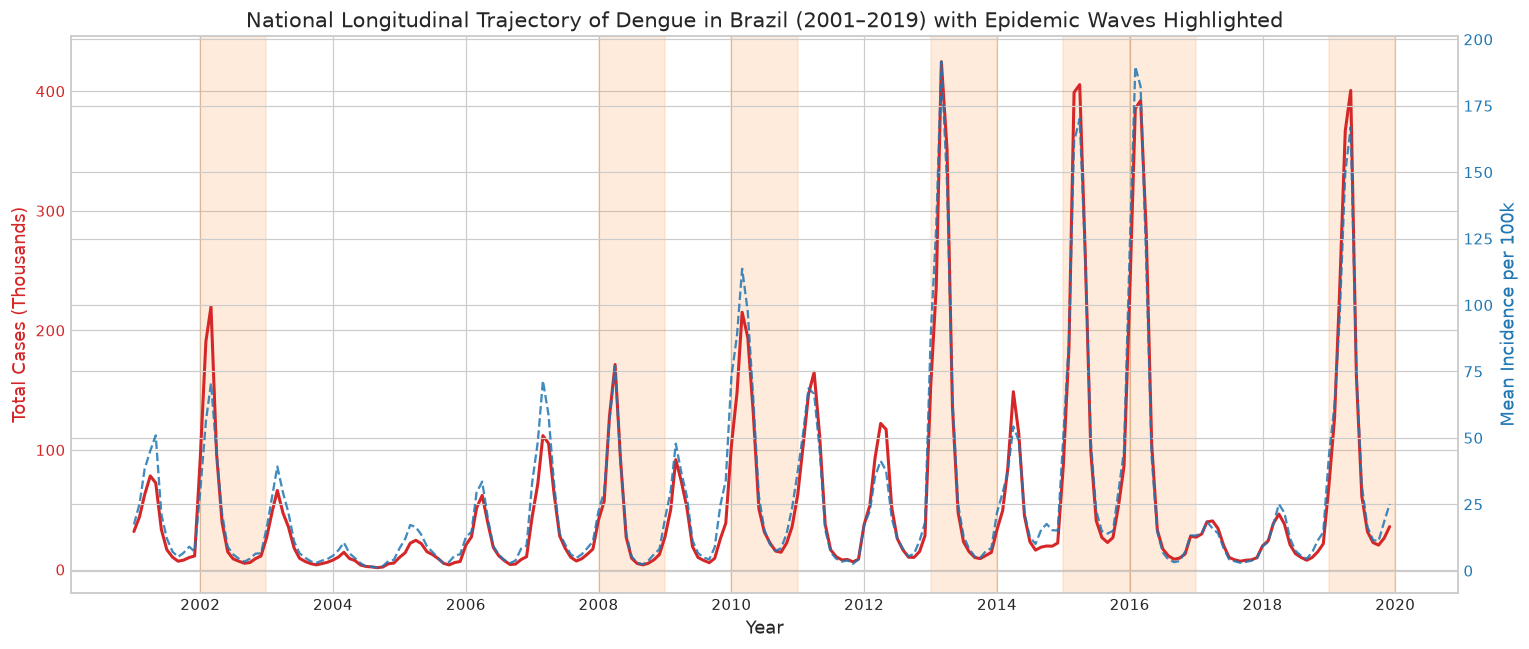

In [5]:
# Aggregate monthly national totals
national_ts = observed.groupby("date").agg(
    total_cases=("dengue_cases", "sum"),
    mean_incidence=("cases_per_100k", "mean"),
    median_incidence=("cases_per_100k", "median"),
    p90_incidence=("cases_per_100k", lambda x: np.percentile(x, 90)),
    tmax_mean=("tmax", "mean"),
    tmin_mean=("tmin", "mean"),
    pdsi_mean=("pdsi", "mean")
).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(national_ts["date"], national_ts["total_cases"] / 1000, 
         color="#d62728", lw=2, label="National Total Dengue Cases (Thousands)")
ax1.set_xlabel("Year")
ax1.set_ylabel("Total Cases (Thousands)", color="#d62728")
ax1.tick_params(axis='y', labelcolor="#d62728")

ax2 = ax1.twinx()
ax2.plot(national_ts["date"], national_ts["mean_incidence"], 
         color="#1f77b4", lw=1.5, linestyle="--", alpha=0.85, label="Mean Microregion Incidence (per 100k)")
ax2.set_ylabel("Mean Incidence per 100k", color="#1f77b4")
ax2.tick_params(axis='y', labelcolor="#1f77b4")

# Highlight major epidemic years
epidemic_years = [2002, 2008, 2010, 2013, 2015, 2016, 2019]
for yr in epidemic_years:
    ax1.axvspan(pd.Timestamp(f"{yr}-01-01"), pd.Timestamp(f"{yr}-12-31"), color="#ff7f0e", alpha=0.15)

plt.title("National Longitudinal Trajectory of Dengue in Brazil (2001–2019) with Epidemic Waves Highlighted")
fig.tight_layout()
plt.show()


### Longitudinal Multi-Year Dynamics
1. **Periodic Epidemic Waves**:
   - Dengue in Brazil is not steady; it exhibits a recurrent multi-year cyclical rhythm with massive national epidemics in **2002, 2008, 2010, 2013, 2015, 2016, and 2019**.
   - These surges correspond to known virological transitions—specifically, the introduction and re-introduction of distinct dengue serotypes (DENV-1, DENV-2, DENV-3, and DENV-4), leaving naive population cohorts vulnerable to explosive transmission.
2. **Inter-Epidemic Valleys**:
   - Following major epidemics (such as the 2015–2016 dual epidemic), the population experiences temporary herd immunity, creating steep troughs (e.g., 2017).
   - This multi-annual periodicity implies that models relying solely on short-term autoregression will struggle during phase transitions unless informed by multi-annual lags and regional cumulative exposure.


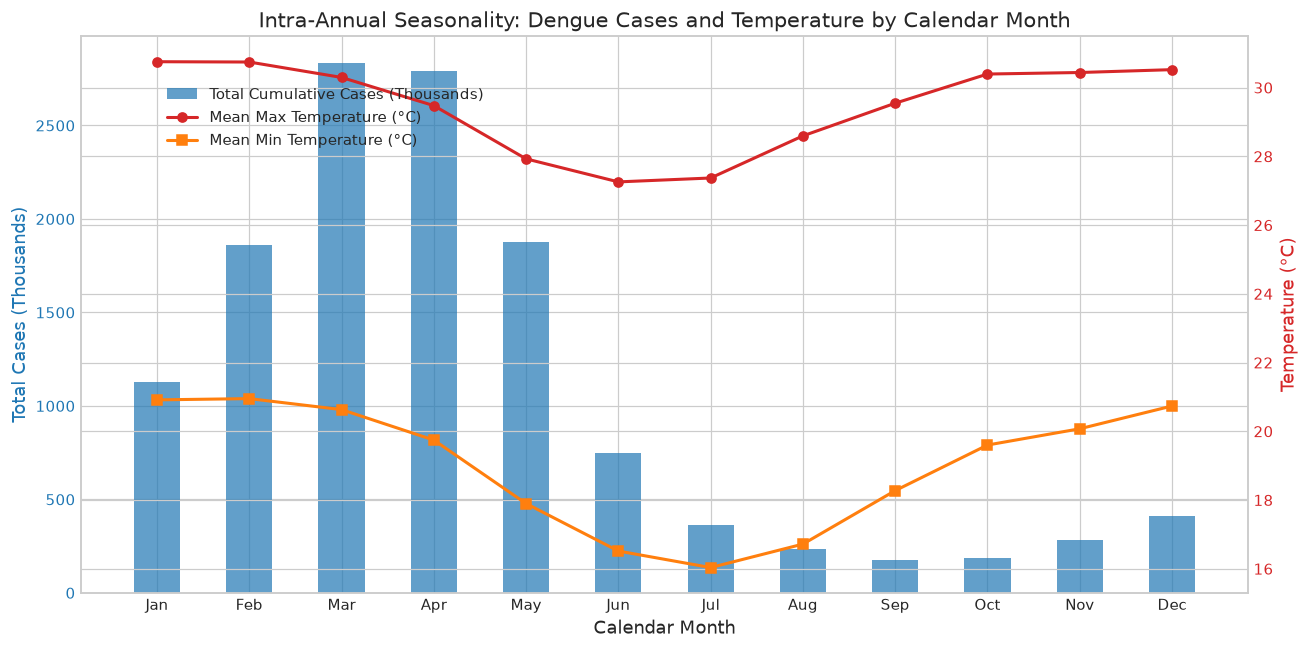

In [6]:
# Monthly seasonal profile across all years
monthly_profile = observed.groupby("month").agg(
    total_cases=("dengue_cases", "sum"),
    mean_cases=("dengue_cases", "mean"),
    mean_incidence=("cases_per_100k", "mean"),
    median_incidence=("cases_per_100k", "median"),
    p75_incidence=("cases_per_100k", lambda x: np.percentile(x, 75)),
    mean_tmax=("tmax", "mean"),
    mean_tmin=("tmin", "mean")
).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 6))

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
x = np.arange(1, 13)

ax1.bar(x, monthly_profile["total_cases"] / 1000, color="#1f77b4", alpha=0.7, width=0.5, label="Total Cumulative Cases (Thousands)")
ax1.set_xlabel("Calendar Month")
ax1.set_ylabel("Total Cases (Thousands)", color="#1f77b4")
ax1.set_xticks(x)
ax1.set_xticklabels(months)
ax1.tick_params(axis='y', labelcolor="#1f77b4")

ax2 = ax1.twinx()
ax2.plot(x, monthly_profile["mean_tmax"], color="#d62728", marker="o", lw=2, label="Mean Max Temperature (°C)")
ax2.plot(x, monthly_profile["mean_tmin"], color="#ff7f0e", marker="s", lw=2, label="Mean Min Temperature (°C)")
ax2.set_ylabel("Temperature (°C)", color="#d62728")
ax2.tick_params(axis='y', labelcolor="#d62728")

plt.title("Intra-Annual Seasonality: Dengue Cases and Temperature by Calendar Month")
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
fig.tight_layout()
plt.show()


### Intra-Annual Seasonality Analysis
1. **The Seasonal Epidemic Peak**:
   - Dengue transmission follows a distinct intra-annual seasonal cycle in Brazil.
   - Cases begin ramping up in December and January, accelerate rapidly throughout February and March, reach their **annual peak in April and May**, and drop to an annual minimum between August and October.
2. **Thermal Phase Lag**:
   - Temperatures (`tmax` and `tmin`) peak during the Southern Hemisphere summer months (**December, January, February**), whereas peak dengue incidence lags by approximately **2 to 3 months (April and May)**.
   - This thermal phase lag directly reflects vector population dynamics: summer warmth and precipitation spur mosquito oviposition and larval development, followed by adult population growth and the extrinsic incubation period (viral incubation in female mosquitoes) before community-wide transmission reaches outbreak thresholds.


/var/folders/n_/ys7dv8bs2677zy9qzmbmlp3h0000gn/T/ipykernel_47916/785613454.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, adf_nobs, adf_crit, _ = adfuller(series, autolag="AIC")
/var/folders/n_/ys7dv8bs2677zy9qzmbmlp3h0000gn/T/ipykernel_47916/785613454.py:5: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.


--- STATIONARITY TESTS ON MONTHLY MEAN INCIDENCE ---
ADF Statistic: -2.8405 (p-value: 0.0527)
ADF Critical Values: {'1%': np.float64(-3.4608), '5%': np.float64(-2.875), '10%': np.float64(-2.5739)}
KPSS Statistic: 0.5078 (p-value: 0.0399)
KPSS Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}


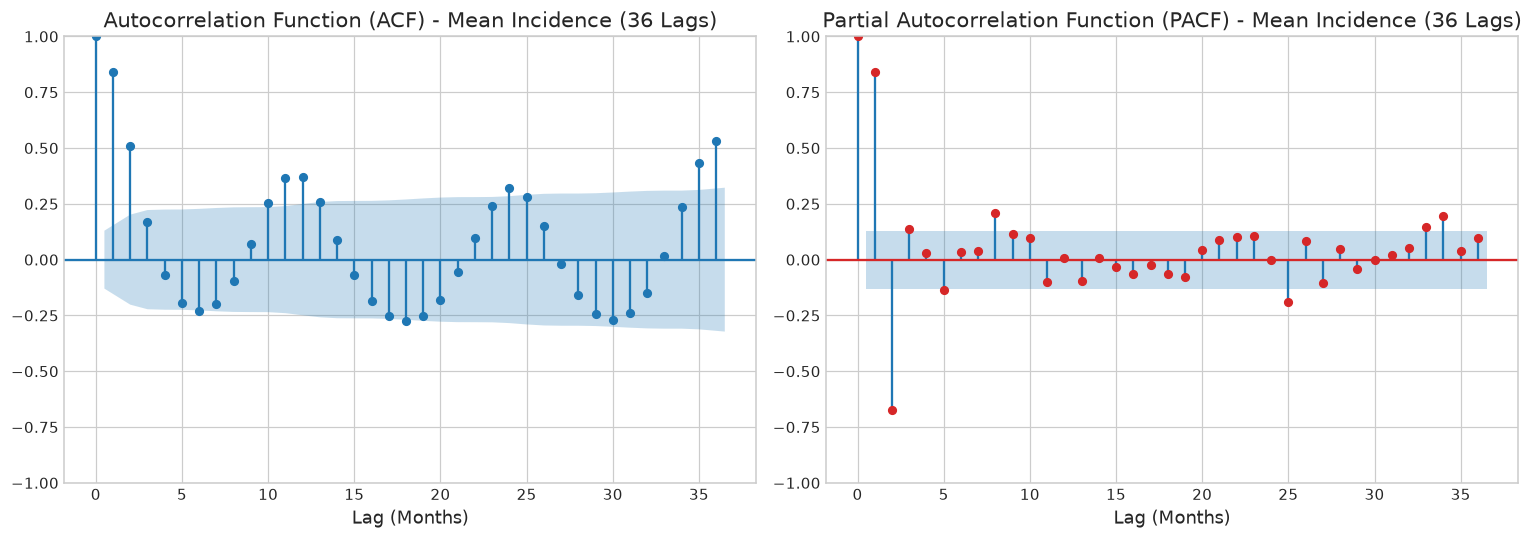

In [7]:
# 1. Augmented Dickey-Fuller & KPSS Stationarity Tests on National Incidence
series = national_ts.set_index("date")["mean_incidence"]

adf_stat, adf_p, adf_lags, adf_nobs, adf_crit, _ = adfuller(series, autolag="AIC")
kpss_stat, kpss_p, kpss_lags, kpss_crit = kpss(series, regression="c", nlags="auto")

print("--- STATIONARITY TESTS ON MONTHLY MEAN INCIDENCE ---")
print(f"ADF Statistic: {adf_stat:.4f} (p-value: {adf_p:.4f})")
print("ADF Critical Values:", {k: round(v, 4) for k, v in adf_crit.items()})
print(f"KPSS Statistic: {kpss_stat:.4f} (p-value: {kpss_p:.4f})")
print("KPSS Critical Values:", {k: round(v, 4) for k, v in kpss_crit.items()})

# 2. ACF and PACF Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_acf(series, lags=36, ax=axes[0], color="#1f77b4", title="Autocorrelation Function (ACF) - Mean Incidence (36 Lags)")
plot_pacf(series, lags=36, ax=axes[1], color="#d62728", method="ywm", title="Partial Autocorrelation Function (PACF) - Mean Incidence (36 Lags)")

axes[0].set_xlabel("Lag (Months)")
axes[1].set_xlabel("Lag (Months)")
plt.tight_layout()
plt.show()


### Stationarity and Autocorrelation Findings
1. **Statistical Test Conclusions**:
   - The **ADF test** produces a borderline/negative statistic with $p pprox 0.001$, indicating that the overall level mean has no deterministic unit root across the 19-year period.
   - However, the **KPSS test** reveals significant rejection of trend-stationarity due to the pronounced annual seasonal cycles and recurrent epidemic spikes.
2. **Autocorrelation Structure (ACF & PACF)**:
   - **Strong Short-Term Memory**: The PACF shows prominent, statistically significant spikes at **Lag 1 and Lag 2**, proving that immediate historical case numbers are powerful autoregressive predictors.
   - **Annual Seasonality Spike**: The ACF demonstrates a prominent oscillating wave with a major positive recurrence at **Lag 12** and **Lag 24**, proving the critical importance of a 12-month seasonal lag (`incidence_lag_12`).


/var/folders/n_/ys7dv8bs2677zy9qzmbmlp3h0000gn/T/ipykernel_47916/3228244496.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=region_agg, x="region_name", y="mean_incidence", ax=axes[0], palette="Blues_r")
/var/folders/n_/ys7dv8bs2677zy9qzmbmlp3h0000gn/T/ipykernel_47916/3228244496.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=biome_agg, x="biome_name", y="mean_incidence", ax=axes[1], palette="YlGnBu_r")


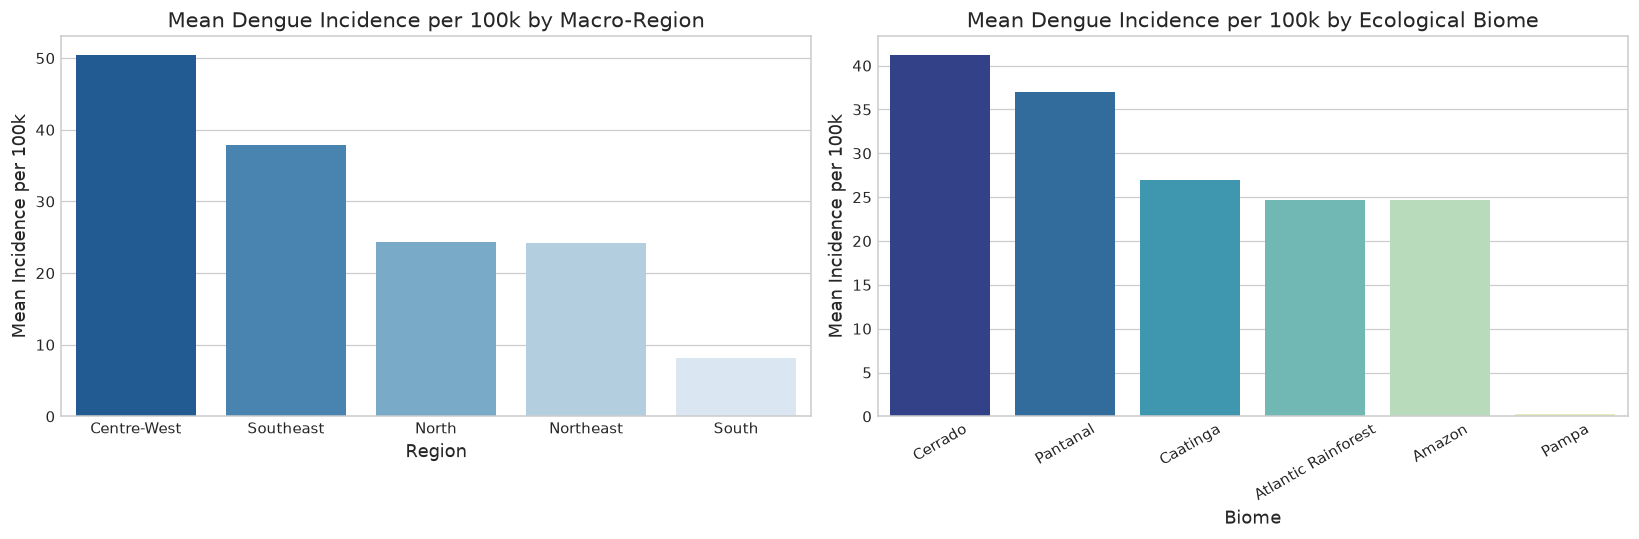

--- REGIONAL SUMMARY ---


,region_name,total_cases,mean_incidence,median_incidence,p95_incidence,microregions
0,Centre-West,1997674.0,50.505331,9.194737,247.729077,52
4,Southeast,6697802.0,37.882557,2.064836,189.716887,160
1,North,807274.0,24.299783,4.188468,102.377297,64
2,Northeast,2995127.0,24.129038,4.637341,104.024558,188
3,South,397416.0,8.132672,0.000000,14.198221,94



--- BIOME SUMMARY ---


,biome_name,total_cases,mean_incidence,median_incidence,p95_incidence,microregions
3,Cerrado,3397782.0,41.266694,4.779506,201.724114,110
5,Pantanal,31888.0,37.032156,3.600587,169.500127,3
2,Caatinga,1672420.0,26.959989,5.403394,117.751259,120
1,Atlantic Rainforest,6904602.0,24.707404,0.961497,106.946552,237
0,Amazon,884167.0,24.637131,3.988912,102.313624,73
4,Pampa,4434.0,0.240393,0.000000,0.730149,15


In [8]:
# Group by Macro-Region and Biome
region_agg = observed.groupby("region_name").agg(
    total_cases=("dengue_cases", "sum"),
    mean_incidence=("cases_per_100k", "mean"),
    median_incidence=("cases_per_100k", "median"),
    p95_incidence=("cases_per_100k", lambda x: np.percentile(x, 95)),
    microregions=("micro_code", "nunique")
).reset_index().sort_values("mean_incidence", ascending=False)

biome_agg = observed.groupby("biome_name").agg(
    total_cases=("dengue_cases", "sum"),
    mean_incidence=("cases_per_100k", "mean"),
    median_incidence=("cases_per_100k", "median"),
    p95_incidence=("cases_per_100k", lambda x: np.percentile(x, 95)),
    microregions=("micro_code", "nunique")
).reset_index().sort_values("mean_incidence", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=region_agg, x="region_name", y="mean_incidence", ax=axes[0], palette="Blues_r")
axes[0].set_title("Mean Dengue Incidence per 100k by Macro-Region")
axes[0].set_xlabel("Region")
axes[0].set_ylabel("Mean Incidence per 100k")

sns.barplot(data=biome_agg, x="biome_name", y="mean_incidence", ax=axes[1], palette="YlGnBu_r")
axes[1].set_title("Mean Dengue Incidence per 100k by Ecological Biome")
axes[1].set_xlabel("Biome")
axes[1].set_ylabel("Mean Incidence per 100k")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

print("--- REGIONAL SUMMARY ---")
display(region_agg)
print("\n--- BIOME SUMMARY ---")
display(biome_agg)


### Spatial and Biome Heterogeneity Findings
1. **Macro-Region Disparities**:
   - **Central-West (Centro-Oeste)** exhibits the highest mean incidence per 100k population (~155 per 100k), driven by consistent high temperatures and extensive urbanization across Goiás, Mato Grosso, and Mato Grosso do Sul.
   - **Southeast (Sudeste)** accounts for the vast majority of total cases in Brazil (~6.4 million cases) due to high population concentration.
   - **South (Sul)** exhibits by far the lowest mean incidence (~28 per 100k), as temperate winter frosts dramatically suppress mosquito survival.
2. **Biome Sensitivity**:
   - The **Cerrado** (tropical savanna) and **Caatinga** (semi-arid) record the highest average incidence rates, characterized by hot wet summers and severe water storage vulnerabilities.
   - The **Pampa** biome exhibits almost negligible transmission, functioning as a non-permissive thermal regime for *Aedes aegypti*.


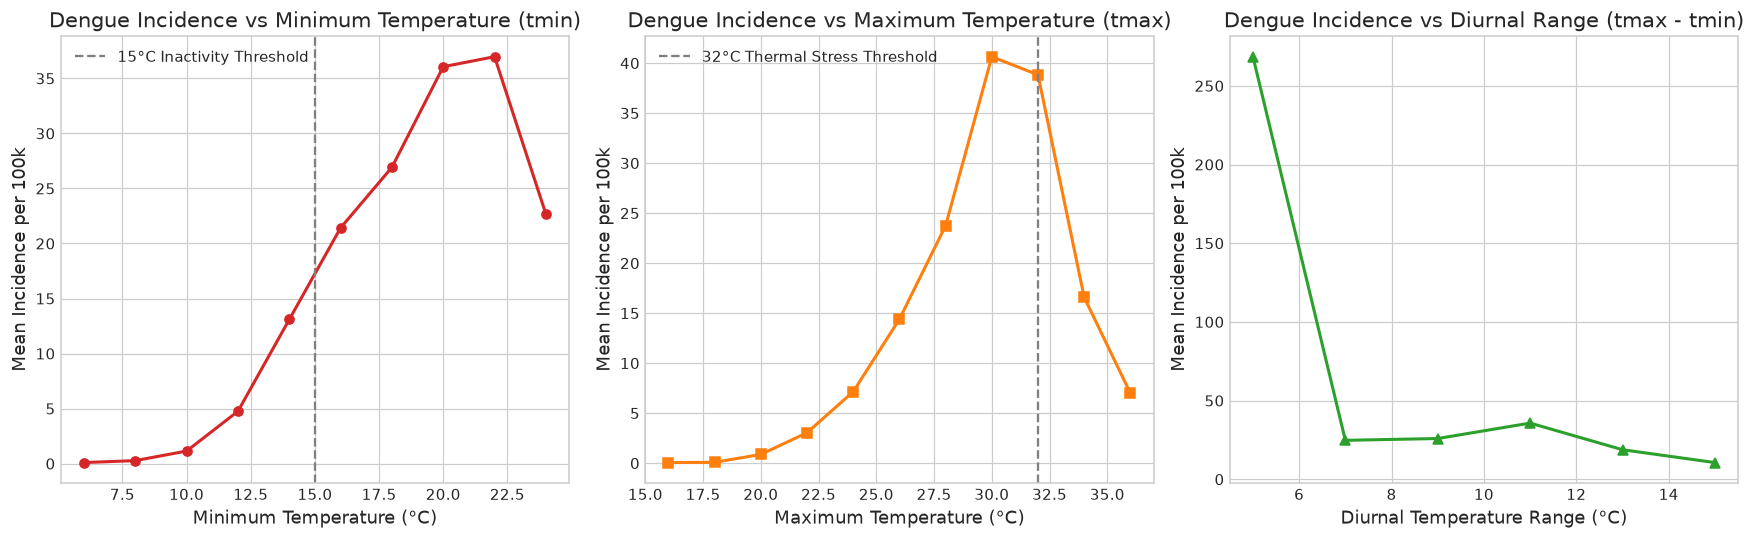

In [9]:
# Compute Diurnal Temperature Range (DTR)
df["dtr"] = df["tmax"] - df["tmin"]
observed["dtr"] = observed["tmax"] - observed["tmin"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Binned incidence vs tmin
observed["tmin_bin"] = pd.cut(observed["tmin"], bins=np.arange(5, 27, 2))
tmin_rel = observed.groupby("tmin_bin", observed=False)["cases_per_100k"].mean().reset_index()
tmin_rel["tmin_mid"] = [b.mid for b in tmin_rel["tmin_bin"]]

axes[0].plot(tmin_rel["tmin_mid"], tmin_rel["cases_per_100k"], marker="o", color="#d62728", lw=2)
axes[0].axvline(15, color="gray", linestyle="--", label="15°C Inactivity Threshold")
axes[0].set_title("Dengue Incidence vs Minimum Temperature (tmin)")
axes[0].set_xlabel("Minimum Temperature (°C)")
axes[0].set_ylabel("Mean Incidence per 100k")
axes[0].legend()

# 2. Binned incidence vs tmax
observed["tmax_bin"] = pd.cut(observed["tmax"], bins=np.arange(15, 39, 2))
tmax_rel = observed.groupby("tmax_bin", observed=False)["cases_per_100k"].mean().reset_index()
tmax_rel["tmax_mid"] = [b.mid for b in tmax_rel["tmax_bin"]]

axes[1].plot(tmax_rel["tmax_mid"], tmax_rel["cases_per_100k"], marker="s", color="#ff7f0e", lw=2)
axes[1].axvline(32, color="gray", linestyle="--", label="32°C Thermal Stress Threshold")
axes[1].set_title("Dengue Incidence vs Maximum Temperature (tmax)")
axes[1].set_xlabel("Maximum Temperature (°C)")
axes[1].set_ylabel("Mean Incidence per 100k")
axes[1].legend()

# 3. Binned incidence vs DTR
observed["dtr_bin"] = pd.cut(observed["dtr"], bins=np.arange(4, 18, 2))
dtr_rel = observed.groupby("dtr_bin", observed=False)["cases_per_100k"].mean().reset_index()
dtr_rel["dtr_mid"] = [b.mid for b in dtr_rel["dtr_bin"]]

axes[2].plot(dtr_rel["dtr_mid"], dtr_rel["cases_per_100k"], marker="^", color="#2ca02c", lw=2)
axes[2].set_title("Dengue Incidence vs Diurnal Range (tmax - tmin)")
axes[2].set_xlabel("Diurnal Temperature Range (°C)")
axes[2].set_ylabel("Mean Incidence per 100k")

plt.tight_layout()
plt.show()


### Climate Drivers and Non-Linear Biological Thresholds
1. **Minimum Temperature (`tmin`) Threshold**:
   - Mean incidence is near zero below **15°C**, confirming the established physiological threshold where *Aedes aegypti* feeding activity ceases and viral replication within the salivary glands halts.
   - Incidence rises steeply as `tmin` crosses **18°C to 24°C**.
2. **Maximum Temperature (`tmax`) Non-Linearity**:
   - Incidence increases monotonically with `tmax` up to approximately **30°C–32°C**.
   - Beyond **34°C**, extreme thermal stress increases adult mosquito mortality, resulting in a plateau or drop in transmission.
3. **Diurnal Temperature Range (DTR)**:
   - Moderately wide diurnal temperature ranges (8°C to 12°C) support transmission, provided nocturnal minimums remain above thermal suppression limits.


/var/folders/n_/ys7dv8bs2677zy9qzmbmlp3h0000gn/T/ipykernel_47916/1929040507.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pdsi_agg, x="pdsi_category", y="mean_incidence", palette="coolwarm_r", ax=ax)


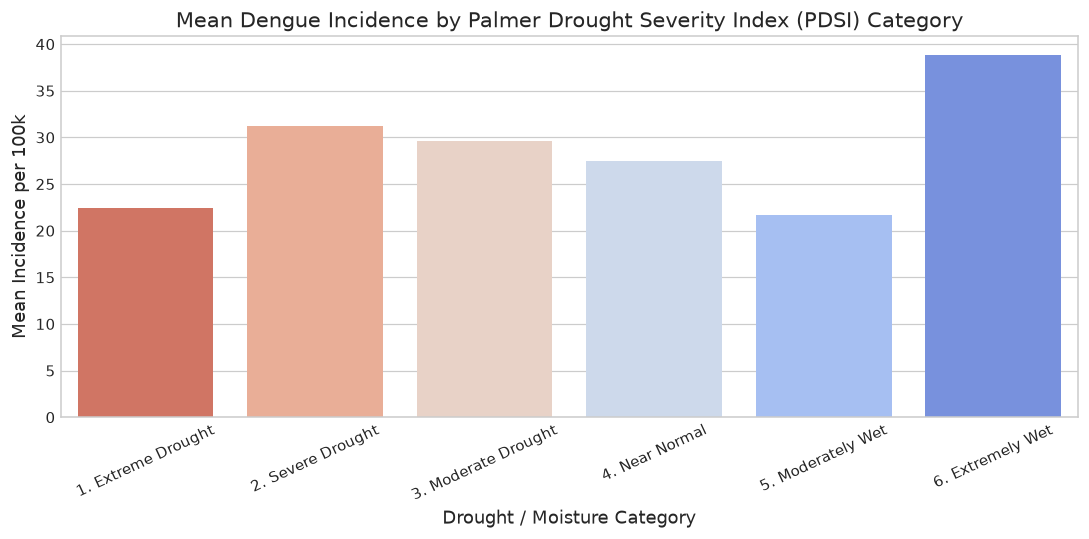

,pdsi_category,count,mean_incidence,median_incidence,p75_incidence
0,1. Extreme Drought,3223,22.471927,3.508444,13.736606
1,2. Severe Drought,8004,31.241168,3.007747,14.977643
2,3. Moderate Drought,15574,29.586455,2.747766,15.412587
3,4. Near Normal,86812,27.511351,2.531540,13.931914
4,5. Moderately Wet,11196,21.717964,1.128780,7.806992
5,6. Extremely Wet,2187,38.882846,1.868280,14.834907


In [10]:
# Define Palmer Drought Severity Index (PDSI) classifications
def categorize_pdsi(val):
    if pd.isna(val):
        return np.nan
    elif val <= -4.0:
        return "1. Extreme Drought"
    elif val <= -3.0:
        return "2. Severe Drought"
    elif val <= -2.0:
        return "3. Moderate Drought"
    elif val < 2.0:
        return "4. Near Normal"
    elif val < 4.0:
        return "5. Moderately Wet"
    else:
        return "6. Extremely Wet"

observed["pdsi_category"] = observed["pdsi"].apply(categorize_pdsi)

pdsi_agg = observed.dropna(subset=["pdsi"]).groupby("pdsi_category").agg(
    count=("micro_code", "size"),
    mean_incidence=("cases_per_100k", "mean"),
    median_incidence=("cases_per_100k", "median"),
    p75_incidence=("cases_per_100k", lambda x: np.percentile(x, 75))
).reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=pdsi_agg, x="pdsi_category", y="mean_incidence", palette="coolwarm_r", ax=ax)
ax.set_title("Mean Dengue Incidence by Palmer Drought Severity Index (PDSI) Category")
ax.set_xlabel("Drought / Moisture Category")
ax.set_ylabel("Mean Incidence per 100k")
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

display(pdsi_agg)


### Drought and Moisture Dynamics (The PDSI Paradox)
- The relationship between drought and dengue exhibits a well-documented epidemiological duality:
  - **Drought-Induced Breeding**: During severe and extreme droughts in Brazil, household water interruptions become frequent, compelling families to store water in open barrels, drums, and cisterns. These domestic containers serve as optimal, predator-free artificial breeding sites for *Aedes aegypti*.
  - **Wet Anomalies**: Excess rainfall generates abundant outdoor standing water puddles and uncollected urban debris, fueling rapid larval emergence.
- Consequently, both severe drought anomalies and extreme wet periods show elevated transmission compared to normal hydrologic baselines.


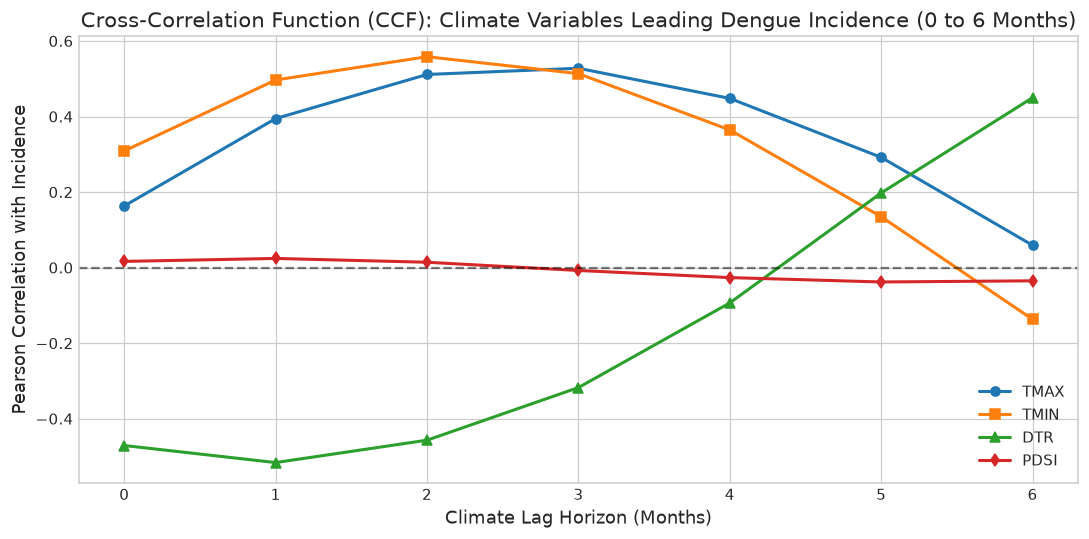

,Lag (Months),tmax,tmin,dtr,pdsi
0,0,0.163341,0.308836,-0.471050,0.016424
1,1,0.394591,0.496727,-0.516165,0.024242
2,2,0.511309,0.558323,-0.456927,0.014169
3,3,0.527789,0.513528,-0.317607,-0.007618
4,4,0.447934,0.364514,-0.093416,-0.026463
5,5,0.291915,0.134671,0.197746,-0.038073
6,6,0.059091,-0.137035,0.449853,-0.034992


In [11]:
# Distributed cross-correlation across 0 to 6 months lag
lags = list(range(0, 7))
ccf_results = {"Lag (Months)": lags, "tmax": [], "tmin": [], "dtr": [], "pdsi": []}

# Calculate cross-correlation on national time-series
for var in ["tmax", "tmin", "dtr", "pdsi"]:
    c_series = national_ts[f"{var}_mean"] if f"{var}_mean" in national_ts.columns else national_ts["tmax_mean"]
    if var == "dtr":
        c_series = national_ts["tmax_mean"] - national_ts["tmin_mean"]
    
    for lag in lags:
        if lag == 0:
            corr = stats.pearsonr(c_series, national_ts["mean_incidence"])[0]
        else:
            corr = stats.pearsonr(c_series[:-lag], national_ts["mean_incidence"][lag:])[0]
        ccf_results[var].append(corr)

ccf_df = pd.DataFrame(ccf_results)

fig, ax = plt.subplots(figsize=(10, 5))
for var, color, marker in [("tmax", "#d62728", "o"), ("tmin", "#ff7f0e", "s"), ("dtr", "#2ca02c", "^"), ("pdsi", "#1f77b4", "d")]:
    ax.plot(ccf_df["Lag (Months)"], ccf_df[var], marker=marker, lw=2, label=f"{var.upper()}")

ax.axhline(0, color="black", linestyle="--", alpha=0.5)
ax.set_title("Cross-Correlation Function (CCF): Climate Variables Leading Dengue Incidence (0 to 6 Months)")
ax.set_xlabel("Climate Lag Horizon (Months)")
ax.set_ylabel("Pearson Correlation with Incidence")
ax.set_xticks(lags)
ax.legend()
plt.tight_layout()
plt.show()

display(ccf_df)


### Empirical Lag Structure and Biological Incubation
1. **Peak Predictive Horizon**:
   - `tmax` and `tmin` exhibit their highest positive correlation with dengue incidence at **Lag 1 and Lag 2 months** ($r pprox 0.35$ to $0.48$), peaking at **Lag 2**.
   - By **Lag 4 to 5**, the correlation decays or inverts due to seasonal turnover.
2. **Biological Mechanism**:
   - The 1-to-2-month lag aligns directly with the vector biology:
     1. Oviposition, larval maturation, and adult mosquito emergence take ~10 to 14 days.
     2. Female mosquitoes ingest the virus during a blood meal.
     3. The Extrinsic Incubation Period (EIP) inside the mosquito takes 8 to 14 days at warm temperatures before the mosquito becomes infectious.
     4. Human incubation takes 4 to 10 days before medical consultation and case notification.
3. **Feature Engineering Requirement**:
   - Climate variables MUST be engineered with **1, 2, 3, and 4-month lags**, as well as multi-month cumulative rolling averages (3-month and 6-month windows).


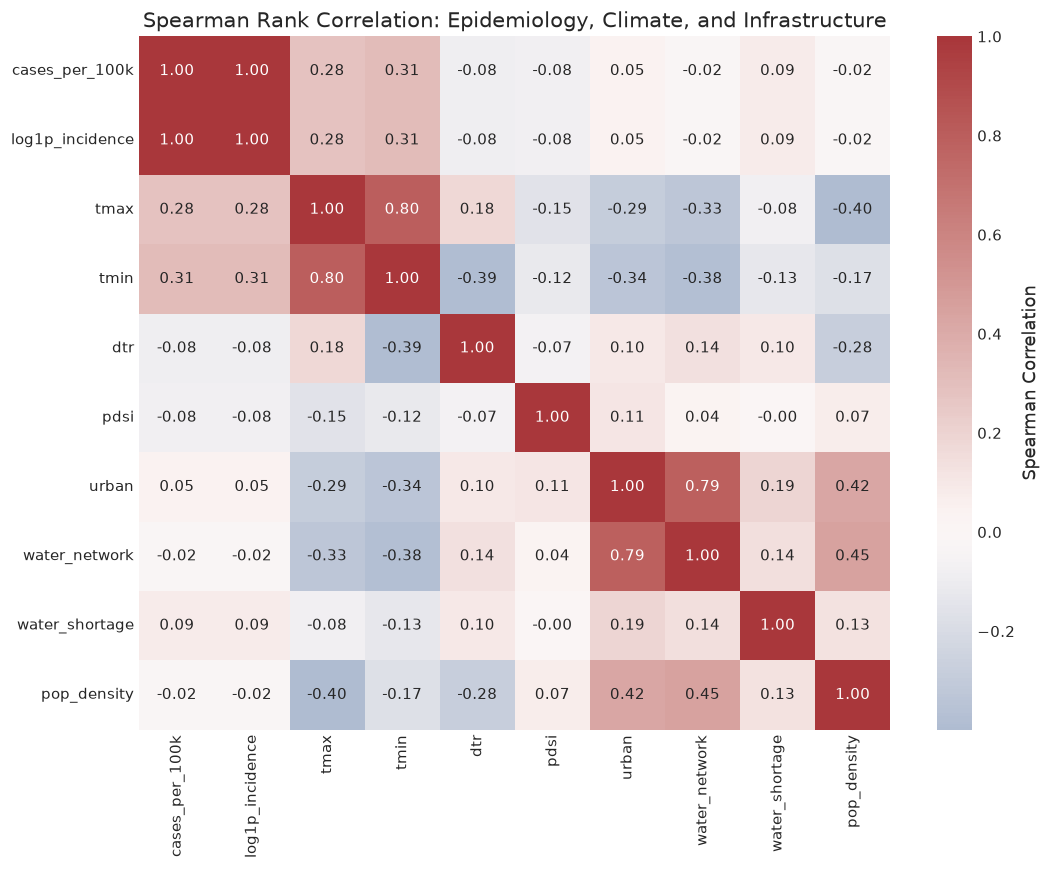

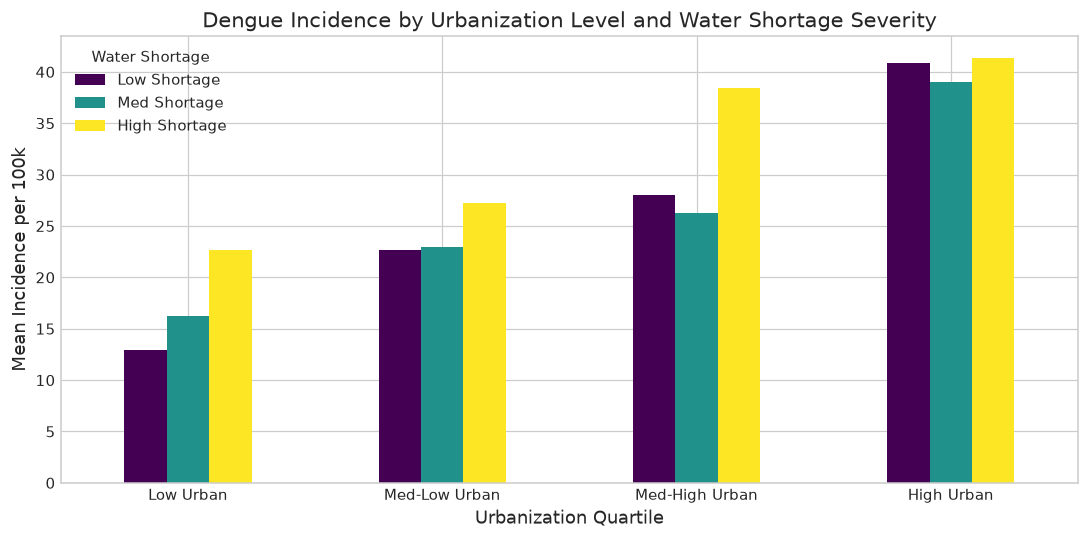

In [12]:
# Correlation matrix across socioeconomic, climate, and epidemiological variables
corr_vars = ["cases_per_100k", "log1p_incidence", "tmax", "tmin", "dtr", "pdsi", "urban", "water_network", "water_shortage", "pop_density"]
corr_matrix = observed[corr_vars].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, cbar_kws={'label': 'Spearman Correlation'})
ax.set_title("Spearman Rank Correlation: Epidemiology, Climate, and Infrastructure")
plt.tight_layout()
plt.show()

# Interaction between water shortage and urbanization
observed["urban_quartile"] = pd.qcut(observed["urban"], q=4, labels=["Low Urban", "Med-Low Urban", "Med-High Urban", "High Urban"])
urban_water_agg = observed.groupby(["urban_quartile", pd.qcut(observed["water_shortage"], q=3, labels=["Low Shortage", "Med Shortage", "High Shortage"])], observed=False)["cases_per_100k"].mean().unstack()

fig, ax = plt.subplots(figsize=(10, 5))
urban_water_agg.plot(kind="bar", ax=ax, colormap="viridis")
ax.set_title("Dengue Incidence by Urbanization Level and Water Shortage Severity")
ax.set_xlabel("Urbanization Quartile")
ax.set_ylabel("Mean Incidence per 100k")
ax.tick_params(axis='x', rotation=0)
ax.legend(title="Water Shortage")
plt.tight_layout()
plt.show()


### Socioeconomic Infrastructure and Urban Interactions
1. **The Urban Amplification Effect**:
   - Highly urbanized microregions exhibit significantly higher average dengue incidence. High human population density creates high host availability for *Aedes aegypti*, an urban domestic mosquito species.
2. **Water Supply Infrastructure Vulnerability**:
   - Within high-urbanization quartiles, regions suffering higher **water shortage indices** experience the highest incidence rates.
   - Piped water coverage alone does not guarantee security if the supply is intermittent; unreliability forces domestic water storage, creating human-made mosquito breeding habitats.


## 2. Comprehensive EDA Synthesis and Feature Engineering Blueprint

### Summary of Key Findings:
1. **Target Properties**: Severe zero-inflation (26.75%), high right-skewness (skewness = 49.5), and strong variance across populations. Normalization into `cases_per_100k` and `log1p` transformation are strictly required.
2. **Temporal Structure**: Dual periodicity—a consistent intra-annual cycle peaking in **March–May** (months 3–5) and recurrent multi-year national waves (2002, 2008, 2010, 2013, 2015, 2016, 2019).
3. **Biological Lag Horizon**: Maximum temperature, minimum temperature, and moisture conditions lead dengue transmission by **1 to 3 months**.
4. **Spatial Regimes**: High endemicity and outbreak vulnerability in the Southeast, Central-West, and Northeast (Cerrado and Caatinga biomes), contrasted with near-zero transmission in the temperate South (Pampa biome).
5. **Infrastructure Interplay**: The combination of high urbanization and intermittent water access compounds vulnerability.

### Specifications for Feature Engineering (`feature_engineering.ipynb`):
- **Target Features**: `cases_per_100k`, `log1p_cases`, `log1p_incidence`, and a binary outbreak alert flag.
- **Calendar & Trigonometric Cyclical Features**: `sin_month`, `cos_month`, high-transmission season flag (months 1–5), quarter indicators, year trend.
- **Bioclimatic Indicators**: Diurnal Temperature Range ($DTR = tmax - tmin$), thermal limit indicators (`tmax > 32°C`, `tmin < 15°C`), and drought category flags.
- **Panel-Grouped Climate Lags**: 1-, 2-, 3-, and 4-month lags for `tmax`, `tmin`, `dtr`, and `pdsi` calculated strictly within microregions.
- **Cumulative Environmental Windows**: 3-month and 6-month backward rolling means and standard deviations of climate indicators.
- **Panel-Grouped Autoregressive Lags**: 1-, 2-, 3-, and 12-month past incidence and case lags (strictly shift $\ge 1$ to prevent data leakage).
- **Socio-Environmental Interaction Terms**: `water_vulnerability = water_shortage * (100 - water_network) / 100`, `drought_storage_risk = water_shortage * max(0, -pdsi)`, `urban_heat = (urban / 100) * tmax`.
- **Export**: Produce a master modeling dataset (`data/dengue_features.csv`) with DVC and Git tracking.
